# Deep learning for healthcare, session 3

**Where deep learning earns its place: images, and the test-set trap**

**Question for today:** can a small neural network read skin lesion images better than a simple model, and is our test actually fair?

In sessions 1 and 2, a neural network did not beat simpler models on intensive care unit (ICU) tables. That is common: when the data are already a tidy table of meaningful columns, simple models are hard to beat. Images are different. A single pixel means almost nothing on its own. What matters is how pixels combine into borders, blotches and colour patterns, and finding such patterns is exactly what neural networks are built for

| Part | What we do | Approx. time |
|---|---|---|
| 1 | Meet the data and audit who is in it | 15 min |
| 2 | A simple baseline: logistic regression on raw pixels | 10 min |
| 3 | How convolution sees an image, then train a small network | 20 min |
| 4 | Is the test really independent? Duplicates and case mix (4.1 can run as optional, saved outputs shown) | 20 min |
| 5 | Check changes to training images | 10 min |
| 6 | Takeaways | 5 min |

**Responsible artificial intelligence (AI) questions today:** *what does it use?* and *who does it miss?* Both start with the data, before any model is trained

## Setup

Locally: create and activate the Conda environment in `environment.yml` as described in the README. Data (about 40 MB) downloads automatically the first time into a `data` folder

### Prepare libraries and plots

Setup code: loads the libraries and fixes the random seed so everyone gets the same results. Run it and move on

In [17]:
# Setup: libraries, reproducibility, plot style
import warnings, time, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from IPython.display import display, Markdown
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore")
SEED = 0
np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(2)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})
NAVY, GREEN, LIME, GREY, RED, ORANGE = "#0b1f4b", "#00a37a", "#9ccf00", "#9aa3ad", "#d1495b", "#f28e2b"

### Prepare image loading

Setup code: downloads the images the first time and reuses the local copy afterwards. Run it and move on

In [18]:
# Data: DermaMNIST (original and corrected) from the authors' public repository, cached in ./data
BASE = "https://raw.githubusercontent.com/kakumarabhishek/Corrected-Skin-Image-Datasets/main/DermaMNIST/DermaMNIST_Analysis/"
FILES = {"corrected": "NPZ_files/dermamnist_corrected_28.npz",
         "original": "NPZ_files/dermamnist_original.npz",
         "meta_corrected": "CSV_files/combined_metadata_corrected-HAM10000_corrected.csv",
         "split_original": "dermamnist_split_info.csv",
         "ham_meta": "HAM10000_metadata.csv"}
DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
def fetch(key):
    path = DATA_DIR / Path(FILES[key]).name
    if not path.exists():
        print("downloading", path.name); urllib.request.urlretrieve(BASE + FILES[key], path)
    return path

CLASSES = {0: "Actinic keratosis (akiec)", 1: "Basal cell carcinoma (bcc)", 2: "Benign keratosis (bkl)",
           3: "Dermatofibroma (df)", 4: "Melanoma (mel)", 5: "Common mole (nv)", 6: "Vascular lesion (vasc)"}
# Actinic keratosis: a rough sun-damage patch that can turn into skin cancer; the group also includes very early skin cancer
CANCER_GROUP = [0, 1, 4]          # possibly cancerous: refer to a dermatologist

def load_split(key):
    d = np.load(fetch(key))
    return {s: {"X": d[f"{s}_images"], "cls": d[f"{s}_labels"].ravel(),
                "y": np.isin(d[f"{s}_labels"].ravel(), CANCER_GROUP).astype(np.float32)} for s in ["train", "val", "test"]}

def load_corrected_with_meta():
    data = load_split("corrected")
    meta = pd.read_csv(fetch("meta_corrected"))          # rows are in the same order as the images within each split
    for s in data:
        data[s]["meta"] = meta[meta.split == s].reset_index(drop=True)
    return data

## 1. The data and who is in it

| Dataset | What it contains | Source |
|---|---|---|
| **HAM10000** | 10,015 dermatoscope images from 7,470 skin lesions, collected in Vienna, Austria, and Queensland, Australia | [Tschandl et al., 2018](https://doi.org/10.1038/sdata.2018.161) |
| **DermaMNIST** | HAM10000 images reduced to 28 x 28 pixels for teaching and model comparisons | [Yang et al., 2023](https://doi.org/10.1038/s41597-022-01721-8) |
| **DermaMNIST corrected** | Images regrouped so photos of the same lesion stay in the same split, with additional fixes for duplicate images and lesion identifiers | [Abhishek et al., 2025](https://doi.org/10.1038/s41597-025-04382-5), [data repository](https://github.com/kakumarabhishek/Corrected-Skin-Image-Datasets) |

A **skin lesion** is any patch of skin that looks different from the skin around it: a mole, a spot, a growth. A **dermatoscope** is a magnifier with its own light that doctors hold against the skin. So these are close-up clinical images, not phone photos

> **Keep in mind:** we shrink every image to 28 x 28 pixels, about the size of an app icon. Training then takes under a minute on a laptop, but much of the detail a dermatologist relies on is gone. Results here teach the method; they say nothing about clinical readiness

**One more limit:** the corrected split keeps all photos of the *same lesion* together. It cannot keep the same *patient* together, because the data have no patient identifier

### View examples of each diagnosis

Before modelling anything, look at the data. Each row is one of seven diagnoses. We merge them into a yes/no task: **positive** (red label) means *possibly cancerous, should see a specialist*; everything else is benign. Could you tell the rows apart?

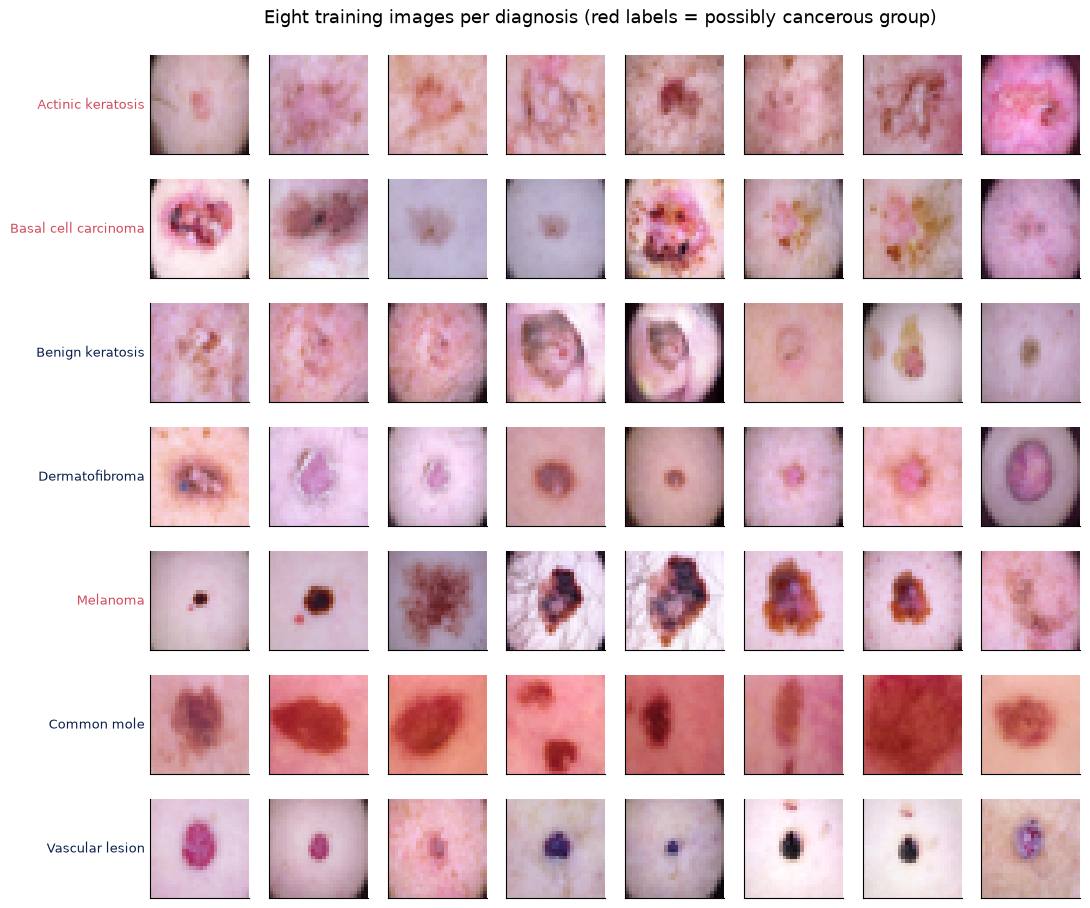

In [19]:
data = load_corrected_with_meta()
X, cls, meta = data["train"]["X"], data["train"]["cls"], data["train"]["meta"]
fig, axes = plt.subplots(7, 8, figsize=(12, 11))
for r in range(7):
    idx = np.where(cls == r)[0][:8]
    for c, i in enumerate(idx):
        ax = axes[r, c]; ax.imshow(X[i]); ax.set_xticks([]); ax.set_yticks([])
        if c == 0: ax.set_ylabel(CLASSES[r].split(" (")[0], rotation=0, ha="right", va="center", fontsize=9,
                                 color=RED if r in CANCER_GROUP else NAVY)
fig.suptitle("Eight training images per diagnosis (red labels = possibly cancerous group)", y=0.92)
plt.show()

**What this shows**

- Each row shows eight examples of one diagnosis. Red labels mark the positive group: melanoma, basal cell carcinoma and actinic keratosis
- Many rows look alike to an untrained eye, especially at this resolution. The model will have to rely on subtle colour and border cues
- **So what?** "Positive" here means *worth a specialist look*, not *cancer*: the group also includes precancerous patches. Good results on the whole group could still hide missed melanomas, so results per diagnosis matter too

### Check who appears in the dataset

A model can only learn from the people in its data. We count diagnoses, then look at age, sex and where the images came from. Ask three questions: who is well represented, who is rare, and what is not recorded at all?

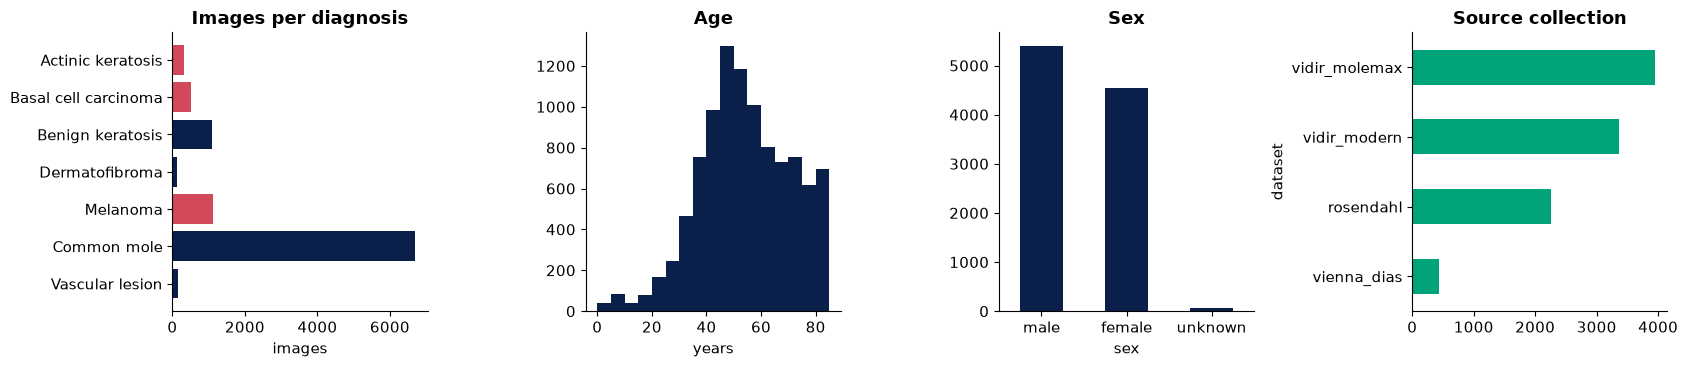

Share possibly cancerous per split: {'train': '21.2%', 'val': '11.0%', 'test': '12.1%'}
Skin tone recorded: no column exists in the metadata -> ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'dataset', 'split', 'set']


In [20]:
allmeta = pd.concat([data[s]["meta"].assign(set=s) for s in data])
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
counts = pd.Series(np.concatenate([data[s]["cls"] for s in data])).value_counts().sort_index()
axes[0].barh([CLASSES[k].split(" (")[0] for k in counts.index], counts.values,
             color=[RED if k in CANCER_GROUP else NAVY for k in counts.index]); axes[0].invert_yaxis()
axes[0].set_title("Images per diagnosis"); axes[0].set_xlabel("images")
axes[1].hist(allmeta.age.dropna(), bins=range(0, 90, 5), color=NAVY); axes[1].set_title("Age"); axes[1].set_xlabel("years")
allmeta.sex.value_counts().plot.bar(ax=axes[2], color=NAVY, rot=0); axes[2].set_title("Sex")
allmeta.dataset.value_counts().plot.barh(ax=axes[3], color=GREEN); axes[3].set_title("Source collection"); axes[3].invert_yaxis()
plt.tight_layout(); plt.show()
share = {s: f"{100*data[s]['y'].mean():.1f}%" for s in data}
print("Share possibly cancerous per split:", share)
print("Skin tone recorded: no column exists in the metadata ->", [c for c in allmeta.columns])

**What this shows**

- Common moles dominate: most images are benign. Positive images are 21.2% of training, 11.0% of validation and 12.1% of test images
- Age, sex and body site are recorded. **Skin tone is not recorded at all.** The images come from Austria and Australia, so lighter skin is probably the majority, but we cannot check
- **So what?** We cannot measure how the model performs on darker skin, so we cannot claim it works there. A clinic with a different patient mix may also see different accuracy and a different referral workload

## 2. A simple baseline: logistic regression on pixels

To a computer, a colour image is just a grid of numbers. Each of our images has 28 x 28 pixels, and each pixel has three brightness values (red, green and blue): 2,352 numbers in total. Unroll them into one long row and an image becomes an ordinary table row, which logistic regression can handle

The catch: logistic regression gives each of the 2,352 positions its own fixed weight. It can learn "a dark pixel *exactly here* pushes towards positive", but it has no idea that neighbouring pixels belong together. Shift a lesion a few pixels to the left and, to this model, it is a completely different input. Keep that weakness in mind: it is what a neural network will try to fix

**Two scores, two questions** (used throughout)

- **AUROC:** pick one positive and one benign image at random. How often does the model give the positive one the higher score? 0.5 is a coin flip, 1.0 is perfect
- **AUPRC:** of the images the model flags, what share are truly positive? AUPRC averages this as the threshold drops to catch more and more positives. A useless model scores the share of positives, about 0.12 on our test set, so 0.4 is far better than it sounds. We compute it as [average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html)

### Train the pixel baseline

We train logistic regression on the unrolled pixels, then draw its 2,352 weights back onto the image grid, one map per colour. This is the benchmark the network has to beat

Pixel logistic regression, test AUROC 0.875, AUPRC 0.425


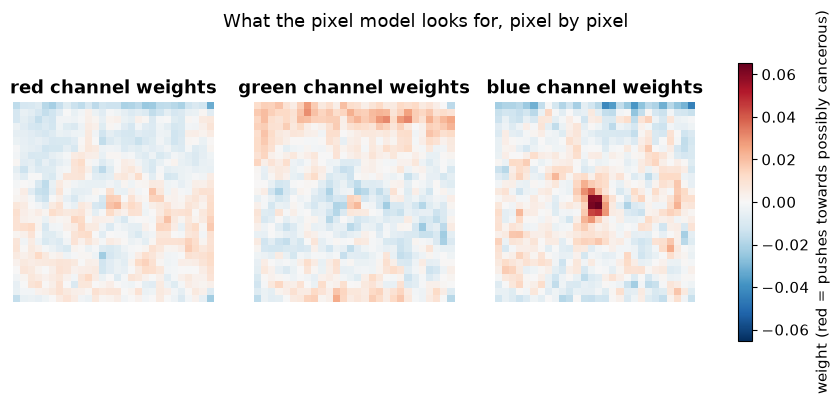

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
flat = {s: data[s]["X"].reshape(len(data[s]["X"]), -1) / 255.0 for s in data}
sc = StandardScaler().fit(flat["train"])
pix = LogisticRegression(C=0.001, max_iter=3000).fit(sc.transform(flat["train"]), data["train"]["y"])
p_pix = pix.predict_proba(sc.transform(flat["test"]))[:, 1]
print(f"Pixel logistic regression, test AUROC {roc_auc_score(data['test']['y'], p_pix):.3f}, AUPRC {average_precision_score(data['test']['y'], p_pix):.3f}")

w = pix.coef_.reshape(28, 28, 3)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for k, name in enumerate(["red", "green", "blue"]):
    v = np.abs(w).max(); im = axes[k].imshow(w[:, :, k], cmap="RdBu_r", vmin=-v, vmax=v)
    axes[k].set_title(f"{name} channel weights"); axes[k].axis("off")
fig.colorbar(im, ax=axes, label="weight (red = pushes towards possibly cancerous)")
fig.suptitle("What the pixel model looks for, pixel by pixel", y=1.02); plt.show()

**What this shows** (output above)

- Each map shows how a pixel's brightness pushes the prediction: red towards positive, blue towards benign
- The maps are mostly speckled noise. The strongest weight is one small spot in the centre of the blue channel, where lesions usually sit. There are also stripes along the top edge, where there is no lesion at all, only the image border
- Even so, the scores are well above chance: 0.875 AUROC and 0.425 AUPRC (chance is 0.5 and about 0.12)
- **So what?** A simple model is a strong starting point, but it learns *where* things tend to be, not *what shape* they have. Weights on image borders are a warning sign that it may be picking up how photos were taken. Any network must clearly beat these numbers to justify its extra complexity

### See the pixel values as a table

This is what the model actually receives. Below are the red, green and blue values of the top-left pixel for five images: just 3 of the 2,352 columns. Values are standardised, so 0 means average brightness and negative means darker than average

In [21]:
display(pd.DataFrame(
    sc.transform(flat["train"][:5])[:, :3],
    columns=["Pixel (0,0) red", "Pixel (0,0) green", "Pixel (0,0) blue"],
    index=[f"Image {i}" for i in range(1, 6)]
))

,"Pixel (0,0) red","Pixel (0,0) green","Pixel (0,0) blue"
Image 1,0.246086,0.474527,1.047349
Image 2,0.246086,0.151411,0.250187
Image 3,-2.261850,-2.368892,-2.181159
Image 4,-0.298400,-0.365574,-0.008891
Image 5,-2.789837,-2.799714,-2.719244


## 3. How a convolutional network sees an image

Think of a **filter** as a small stencil, here 3 x 3 pixels. We slide it across the image, and at every position we ask *how well does this patch match the stencil?* The answer (multiply the 9 pixel values by the 9 stencil weights and add them up) becomes one pixel of a new image, called a **feature map**. Wherever the pattern is present, the feature map lights up

Two ideas make this powerful

- **The same stencil is used everywhere.** A filter that detects a dark border finds it at the top, bottom or side of the image. Logistic regression would have to learn that separately for every position
- **Filters stack.** The first layer finds simple edges and colour spots. The next layer combines these into blobs, rings and textures. Layer by layer, the network sees larger and more complex patterns

A **convolutional neural network (CNN)** learns its own filters from the training data. First, we try three filters designed by hand to see the idea

### Try three simple filters

We slide three hand-made filters over one lesion: one that responds to vertical edges, one to horizontal edges, and one that averages neighbouring pixels, which blurs the image. Before running: which parts of the lesion should light up for the edge filters?

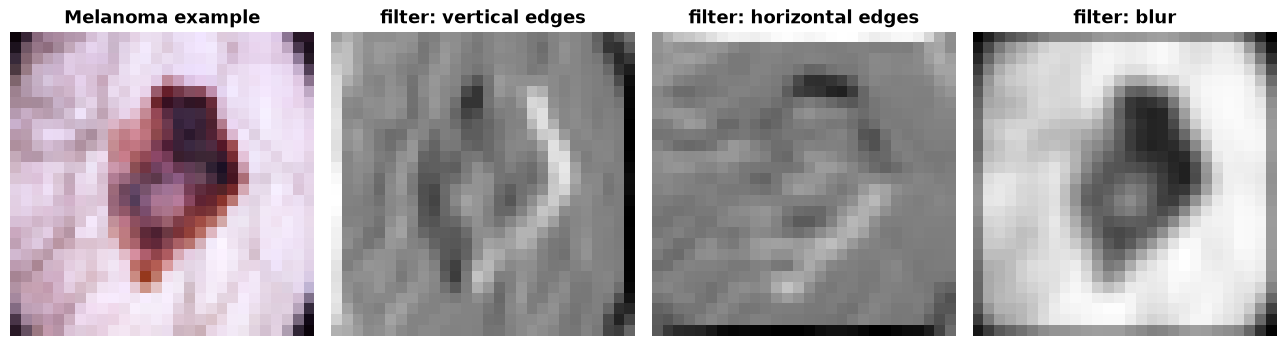

In [23]:
import torch.nn.functional as F
img = data["train"]["X"][np.where(data["train"]["cls"] == 4)[0][3]]
gray = torch.tensor(img.mean(2) / 255.0, dtype=torch.float32)[None, None]
filters = {"vertical edges": [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]],
           "horizontal edges": [[-1, -2, -1], [0, 0, 0], [1, 2, 1]],
           "blur": [[1 / 9] * 3] * 3}
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
axes[0].imshow(img); axes[0].set_title("Melanoma example"); axes[0].axis("off")
for ax, (name, k) in zip(axes[1:], filters.items()):
    out = F.conv2d(gray, torch.tensor(k, dtype=torch.float32)[None, None], padding=1)[0, 0]
    ax.imshow(out, cmap="gray"); ax.set_title(f"filter: {name}"); ax.axis("off")
plt.tight_layout(); plt.show()

**What this shows**

- From left to right: the original lesion, vertical edges, horizontal edges and the blurred image
- The edge filters light up along the lesion border and stay dark on flat skin. Nine numbers were enough to turn "border" into something a model can measure
- **So what?** Borders and colour patches are exactly what dermatologists look at. A CNN starts from filters like these, but chooses the numbers itself, keeping whatever helps it predict

### Define how the network learns

Our network has three blocks of filters: 16, then 32, then 64. After each of the first two blocks, **pooling** halves the image size by keeping the strongest response in each 2 x 2 patch. Shrinking the image means later filters cover a larger area of the lesion. At the end, each of the 64 feature maps is averaged into one number, and these 64 numbers are combined into a single score

Training works like logistic regression, just with many more weights: predict, measure the error, nudge every weight to reduce it, repeat. Two tricks help against memorising the training images

- **Dropout** randomly switches off some of the 64 final numbers during training, so the network cannot rely on any single one
- **Augmentation** randomly mirrors and rotates each training image. We test whether this helps in section 5

This cell only defines the recipe; the next cell runs it

In [24]:
class SmallCNN(nn.Module):
    """Three convolution blocks, then average over the image and one output neuron"""
    def __init__(self, p_drop=0.3):
        super().__init__()
        self.features = nn.Sequential(  # Fix the network size: 16, then 32, then 64 filters
            nn.Conv2d(3, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU())
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(p_drop),
            nn.Linear(64, 1))
    def forward(self, x):
        return self.head(self.features(x))


def to_tensor(X, mu, sd):
    """uint8 images (n, 28, 28, 3) -> normalised float tensor (n, 3, 28, 28)"""
    return torch.tensor(((X / 255.0 - mu) / sd).transpose(0, 3, 1, 2), dtype=torch.float32)


def augment(x):
    """Label-preserving changes for dermoscopy: mirror and rotate by 90 degree steps"""
    if np.random.rand() < 0.5: x = x.flip(3)
    if np.random.rand() < 0.5: x = x.flip(2)
    return torch.rot90(x, np.random.randint(4), (2, 3))


def predict_cnn(model, T, batch=1024):
    model.eval()  # Use prediction settings: turn dropout off and freeze normalisation statistics
    with torch.no_grad():  # Make predictions without calculating weight updates
        return np.concatenate([torch.sigmoid(model(T[i:i + batch])).numpy().ravel() for i in range(0, len(T), batch)])


def train_cnn(Xtr, ytr, Xva, yva, epochs=15, use_augment=True, seed=0, verbose=True):
    """Adam, batches of 128, keep the epoch with the best validation AUROC. Returns model, normalisation and history"""
    np.random.seed(seed); torch.manual_seed(seed)
    mu, sd = (Xtr / 255.0).mean((0, 1, 2)), (Xtr / 255.0).std((0, 1, 2))  # Calculate colour scaling from training images only
    Ttr, Tva, yt = to_tensor(Xtr, mu, sd), to_tensor(Xva, mu, sd), torch.tensor(ytr)
    model = SmallCNN()  # Start with randomly initialised weights in the fixed architecture
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)  # Choose the update method and learning rate
    lossf = nn.BCEWithLogitsLoss()
    hist, best, state, t0 = [], -1, None, time.time()
    for ep in range(epochs):  # Limit training to the specified number of full passes
        model.train()
        perm = torch.randperm(len(yt))
        tot = 0
        for i in range(0, len(yt), 128):
            b = perm[i:i + 128]
            x = augment(Ttr[b]) if use_augment else Ttr[b]
            opt.zero_grad()
            loss = lossf(model(x).squeeze(1), yt[b])  # Compare this batch of predictions with the correct labels
            loss.backward()  # Calculate how each weight affects the prediction error
            opt.step()  # Adjust the weights using the error signal
            tot += loss.item() * len(b)
        pva = predict_cnn(model, Tva)  # Check validation images without learning from them
        auc = roc_auc_score(yva, pva)
        auprc = average_precision_score(yva, pva)
        hist.append({"epoch": ep + 1, "train_loss": tot / len(yt), "val_auroc": auc, "val_auprc": auprc})
        if auc > best:  # Keep the version with the best validation ranking
            best, best_auprc, state = auc, auprc, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(state); model.eval()  # Restore the selected version, which may come from an earlier pass
    if verbose: print(f"trained {epochs} epochs in {time.time() - t0:.0f} s, selected validation AUROC {best:.3f}, AUPRC {best_auprc:.3f}")
    return model, (mu, sd), pd.DataFrame(hist)


### Train and compare the network

We train for 15 **epochs** (one epoch is one pass through all training images) and keep the epoch with the best validation score. Then we compare the network with the pixel baseline on the same test images, with a 95% confidence interval for the gap, to check that the improvement is not just luck. The model is saved for sessions 4 and 5

trained 15 epochs in 26 s, selected validation AUROC 0.960, AUPRC 0.718
Parameters: pixel logistic regression 2,353 | CNN 23,873
Test set: 1227 images from 1149 lesions
Test AUROC: pixels + logistic 0.875 | CNN 0.944 | gap +0.069, 95% CI +0.045 to +0.093
Test AUPRC: pixels + logistic 0.425 | CNN 0.665 | gap +0.240, 95% CI +0.150 to +0.321


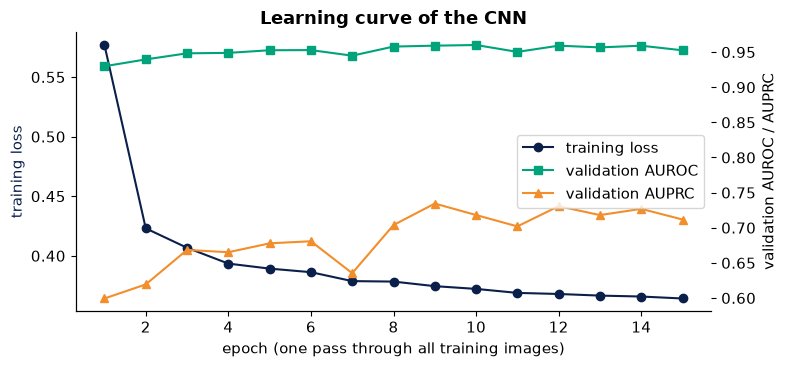

In [25]:
model, (mu, sd), hist = train_cnn(data["train"]["X"], data["train"]["y"], data["val"]["X"], data["val"]["y"], seed=0)
T = {s: to_tensor(data[s]["X"], mu, sd) for s in data}
p_cnn = predict_cnn(model, T["test"]); yte = data["test"]["y"]
print(f"Parameters: pixel logistic regression {pix.coef_.size + 1:,} | CNN {sum(q.numel() for q in model.parameters()):,}")

# Lesion-level bootstrap: resample lesions, not images, because a few test lesions have more than one photo
rng = np.random.default_rng(0)
les = data["test"]["meta"].lesion_id.values; uniq = np.unique(les); rows_of = {g: np.where(les == g)[0] for g in uniq}
print(f"Test set: {len(yte)} images from {len(uniq)} lesions")
B = [np.concatenate([rows_of[g] for g in rng.choice(uniq, len(uniq))]) for _ in range(2000)]
for metric, score in [("AUROC", roc_auc_score), ("AUPRC", average_precision_score)]:
    gaps = [score(yte[b], p_cnn[b]) - score(yte[b], p_pix[b]) for b in B]
    print(f"Test {metric}: pixels + logistic {score(yte, p_pix):.3f} | CNN {score(yte, p_cnn):.3f} | "
          f"gap {score(yte, p_cnn) - score(yte, p_pix):+.3f}, 95% CI {np.percentile(gaps, 2.5):+.3f} to {np.percentile(gaps, 97.5):+.3f}")

fig, ax = plt.subplots(figsize=(8, 3.8)); ax2 = ax.twinx()
ax.plot(hist.epoch, hist.train_loss, "o-", color=NAVY, label="training loss"); ax.set_ylabel("training loss", color=NAVY)
ax2.plot(hist.epoch, hist.val_auroc, "s-", color=GREEN, label="validation AUROC"); ax2.set_ylabel("validation AUROC / AUPRC")
ax2.plot(hist.epoch, hist.val_auprc, "^-", color=ORANGE, label="validation AUPRC"); lines = ax.get_lines() + ax2.get_lines()
ax2.legend(lines, [line.get_label() for line in lines], loc="center right")
ax.set_xlabel("epoch (one pass through all training images)"); ax.set_title("Learning curve of the CNN"); plt.tight_layout(); plt.show()

# Save for sessions 4 and 5
Path("models").mkdir(exist_ok=True)
torch.save({"state": model.state_dict(), "mu": mu, "sd": sd, "data": "dermamnist_corrected_28.npz", "seed": 0, "torch": torch.__version__}, "models/cnn_corrected_seed0.pt")

**What this shows** (output above)

- Dark blue (left axis): training error drops sharply in the first two epochs, then flattens. Green and orange (right axis): validation scores rise and level off after about eight epochs, when extra training stops helping much
- The network has about ten times more weights than logistic regression (23,873 versus 2,353), and scores clearly higher: AUROC 0.944 versus 0.875, AUPRC 0.665 versus 0.425
- The confidence intervals for both gaps stay well above zero, so the gain is not just luck in which test images we got. It is still one training run; repeating with other random starting weights would show how stable it is
- **So what?** On images, unlike ICU tables, the network earns its place. Shared filters let it learn shapes and borders that a pixel-by-pixel model cannot. Next question: was the test that produced these numbers fair?

### Inspect the filters training produced

What did the network actually learn? Top row: its 16 first-layer filters, each a tiny 3 x 3 colour stencil. Bottom row: where each filter responds on one melanoma image

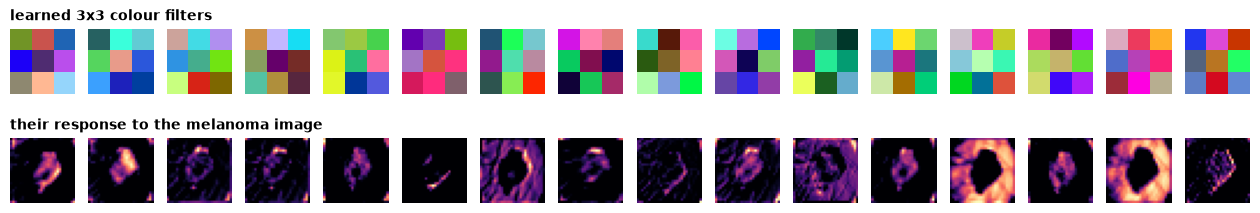

In [26]:
# What did the first layer learn? Its 16 filters, and their responses to one image
W1 = model.features[0].weight.detach().numpy()          # 16 filters x 3 colours x 3 x 3
fig, axes = plt.subplots(2, 16, figsize=(16, 2.6))
with torch.no_grad():
    maps = model.features[:3](T["train"][[np.where(data["train"]["cls"] == 4)[0][3]]])[0].numpy()
for k in range(16):
    f = W1[k].transpose(1, 2, 0); f = (f - f.min()) / (f.max() - f.min() + 1e-9)
    axes[0, k].imshow(f); axes[0, k].axis("off")
    axes[1, k].imshow(maps[k], cmap="magma"); axes[1, k].axis("off")
axes[0, 0].set_title("learned 3x3 colour filters", loc="left", fontsize=10)
axes[1, 0].set_title("their response to the melanoma image", loc="left", fontsize=10)
plt.show()

**What this shows**

- Top: the 16 learned filters. Bottom: their feature maps on the same melanoma, where bright means "this pattern is here"
- Some filters respond inside the lesion, some trace its border, and some light up the surrounding skin. Nobody told the network to look for these; it kept them because they helped it predict
- **So what?** It is tempting to name filters ("the border detector"), but one image is not evidence. A filter that fires on background skin, hair or image corners may be learning *how the photo was taken* rather than the disease. Session 4 tests exactly this

## 4. Is the test really independent?

A test score only means something if the test cases are truly new to the model. Think of a student who saw the exam questions while studying: a high grade says little about what they learned

HAM10000 often has several photos of the same lesion, at different angles or zoom levels. If one photo lands in training and another in the test set, the model is graded on a lesion it has already studied. This is **data leakage**. The original DermaMNIST split had this problem, because it split *images* rather than *lesions*. The corrected version keeps all photos of a lesion together. How big was the problem?

### Check for lesions shared across splits

We count how many test images in the original split show a lesion that also appears in training, and show some of these pairs side by side

Original DermaMNIST: 693 of 2005 test images (35%) show a lesion that also appears in training
Corrected DermaMNIST: 0 test images share a lesion with training


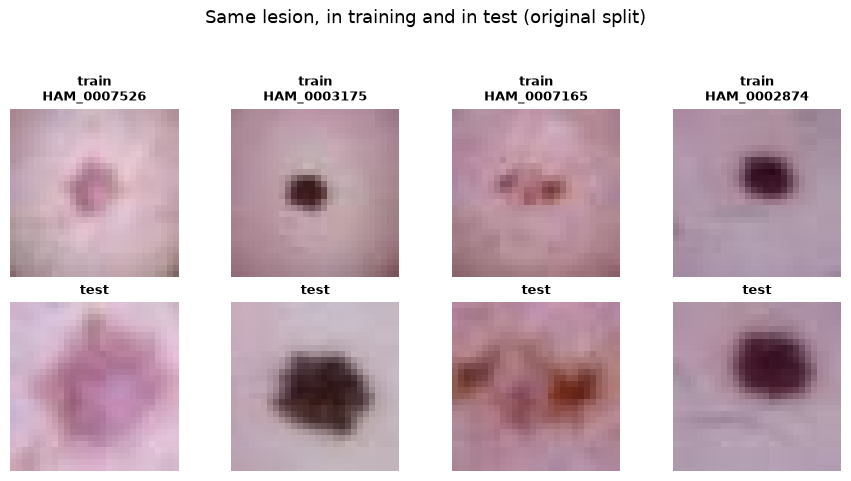

In [27]:
split_o = pd.read_csv(fetch("split_original")).merge(pd.read_csv(fetch("ham_meta")), on="image_id")
train_lesions = set(split_o[split_o.split == "train"].lesion_id)
test_o = split_o[split_o.split == "test"]
shared = test_o.lesion_id.isin(train_lesions)
print(f"Original DermaMNIST: {shared.sum()} of {len(test_o)} test images ({shared.mean():.0%}) show a lesion that also appears in training")
corr = allmeta
print(f"Corrected DermaMNIST: {corr[corr.set == 'test'].lesion_id.isin(set(corr[corr.set == 'train'].lesion_id)).sum()} test images share a lesion with training")

# Show three lesions that appear in both original training and test sets
ex = test_o[shared].drop_duplicates("lesion_id").head(4)
orig = np.load(fetch("original"))
fig, axes = plt.subplots(2, 4, figsize=(9, 4.6))
for c, (_, r) in enumerate(ex.iterrows()):
    tr_row = split_o[(split_o.lesion_id == r.lesion_id) & (split_o.split == "train")].iloc[0]
    axes[0, c].imshow(orig["train_images"][tr_row["index"]]); axes[0, c].set_title(f"train\n{r.lesion_id}", fontsize=9)
    axes[1, c].imshow(orig["test_images"][r["index"]]); axes[1, c].set_title("test", fontsize=9)
for ax in axes.ravel(): ax.axis("off")
fig.suptitle("Same lesion, in training and in test (original split)", y=1.04); plt.tight_layout(); plt.show()

**What this shows**

- Each column pairs a training photo with a test photo of the *same* lesion in the original split. Many pairs look nearly identical
- **35% of the original test images** (693 of 2,005) show a lesion the model had already trained on. The corrected split has none
- **So what?** Split by the unit you want the model to generalise to: the lesion, or better still, the patient. Most code splits rows at random by default, and that quietly leaks. Our corrected split still cannot keep patients together, because patient identifiers are missing

### 4.1 How much does leakage change the score? A controlled experiment

*Optional to run live (about 2 minutes); saved outputs are shown. Section 4.2 uses its results, so run in order*

To isolate the effect of leakage, we train the same network twice and change only one thing

1. Set aside 20% of lesions for testing, one photo each. Any other photos of those test lesions are their **sibling photos**
2. **Clean training:** train only on the remaining lesions
3. **Leaky training:** the same, but swap some training images for sibling photos of test lesions. Training size and test images stay exactly the same
4. Compare test scores, then repeat with a second random seed

Swapping images also changes the training mix slightly, so this is a good, but not perfect, isolation

#### Compare training with and without leakage

Each plot connects clean and leaky scores for the same cases, with the two runs shown separately. Additional photos show the same lesion and enter training only in the leaky condition. The small table summarises changes across all test lesions.

Run 1: 1,494 test lesions, including 387 with additional photos


Run 2: 1,494 test lesions, including 417 with additional photos


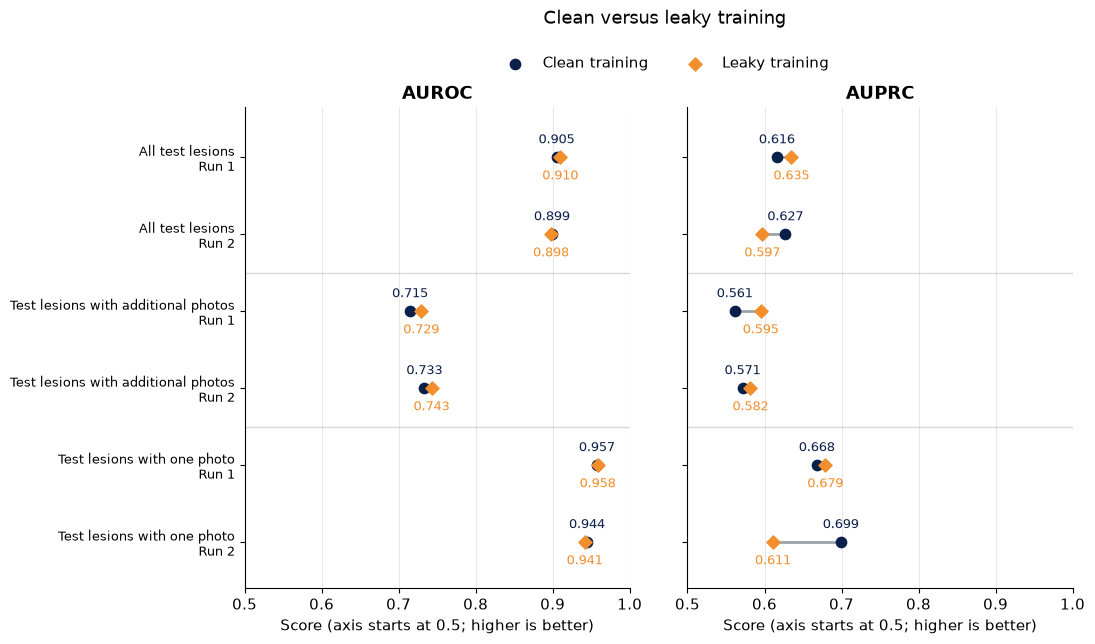

Overall change: leaky minus clean; positive means leaky training scored higher


,AUROC change,AUPRC change
Run,,
1,+0.005,+0.019
2,-0.001,-0.030


In [28]:
from sklearn.model_selection import GroupShuffleSplit, train_test_split
Xall = np.concatenate([data[s]["X"] for s in data]); yall = np.concatenate([data[s]["y"] for s in data])
gall = np.concatenate([data[s]["meta"].lesion_id.values for s in data])
rows = []
for seed in [0, 1]:
    rng_l = np.random.default_rng(seed)
    pool_tr, pool_te = next(GroupShuffleSplit(1, test_size=0.2, random_state=seed).split(Xall, yall, gall))
    held = pd.DataFrame({"i": pool_te, "g": gall[pool_te]}).sample(frac=1, random_state=seed)
    test_idx = held.drop_duplicates("g").i.values                       # one photo per held-out lesion
    siblings = np.setdiff1d(pool_te, test_idx)                           # the other photos of those lesions
    has_sib = np.isin(gall[test_idx], gall[siblings])
    in_tr, in_va = next(GroupShuffleSplit(1, test_size=0.1, random_state=seed).split(pool_tr, groups=gall[pool_tr]))
    clean_tr, va = pool_tr[in_tr], pool_tr[in_va]
    leaky_tr = np.concatenate([np.setdiff1d(clean_tr, rng_l.choice(clean_tr, len(siblings), replace=False)), siblings])
    for name, a in {"clean training": clean_tr, "leaky training": leaky_tr}.items():
        m, (mu_, sd_), _ = train_cnn(Xall[a], yall[a], Xall[va], yall[va], seed=seed, verbose=False)
        pt = predict_cnn(m, to_tensor(Xall[test_idx], mu_, sd_)); yy = yall[test_idx]
        rows.append({"seed": seed, "training": name, "training images": len(a), "test images": len(test_idx),
                     "AUROC, all test images": roc_auc_score(yy, pt), "AUPRC, all test images": average_precision_score(yy, pt),
                     f"AUROC, lesions with a sibling": roc_auc_score(yy[has_sib], pt[has_sib]), "AUPRC, lesions with a sibling": average_precision_score(yy[has_sib], pt[has_sib]),
                     "AUROC, lesions without": roc_auc_score(yy[~has_sib], pt[~has_sib]), "AUPRC, lesions without": average_precision_score(yy[~has_sib], pt[~has_sib])})
    print(f"Run {seed + 1}: {len(test_idx):,} test lesions, including {has_sib.sum()} with additional photos")
leak = pd.DataFrame(rows)
# Compare the same cases side by side; each line connects clean and leaky training.
groups = [("All test lesions", "all test images"),
          ("Test lesions with additional photos", "lesions with a sibling"),
          ("Test lesions with one photo", "lesions without")]
fig, axes = plt.subplots(1, 2, figsize=(12, 6.5), sharey=True)
positions, labels = [], []
for group_index, (group_label, suffix) in enumerate(groups):
    for run_index, seed in enumerate([0, 1]):
        ypos = 5 - (2 * group_index + run_index)
        positions.append(ypos)
        labels.append(f"{group_label}\nRun {seed + 1}")
        for ax, metric in zip(axes, ["AUROC", "AUPRC"]):
            column = f"{metric}, {suffix}"
            clean = leak.loc[(leak.seed == seed) & (leak.training == "clean training"), column].iloc[0]
            leaky = leak.loc[(leak.seed == seed) & (leak.training == "leaky training"), column].iloc[0]
            ax.plot([clean, leaky], [ypos, ypos], color=GREY, lw=2, zorder=1)
            ax.scatter(clean, ypos, color=NAVY, marker="o", s=55, zorder=3, label="Clean training" if ypos == 5 else None)
            ax.scatter(leaky, ypos, color=ORANGE, marker="D", s=45, zorder=3, label="Leaky training" if ypos == 5 else None)
            ax.annotate(f"{clean:.3f}", (clean, ypos), xytext=(0, 10), textcoords="offset points",
                        ha="center", color=NAVY, fontsize=9)
            ax.annotate(f"{leaky:.3f}", (leaky, ypos), xytext=(0, -16), textcoords="offset points",
                        ha="center", color=ORANGE, fontsize=9)
for ax, metric in zip(axes, ["AUROC", "AUPRC"]):
    ax.set_title(metric)
    ax.set_xlim(0.5, 1.0)  # Use the same focused score range for both panels.
    ax.set_ylim(-0.6, 5.65)
    ax.set_xlabel("Score (axis starts at 0.5; higher is better)")
    ax.set_yticks(positions)
    ax.set_axisbelow(True)
    ax.grid(axis="x", color=GREY, alpha=0.25)
    ax.axhline(3.5, color=GREY, alpha=0.4, lw=1)
    ax.axhline(1.5, color=GREY, alpha=0.4, lw=1)
axes[0].set_yticklabels(labels, fontsize=9)
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper center", bbox_to_anchor=(0.64, 0.96), ncol=2, frameon=False)
fig.suptitle("Clean versus leaky training", x=0.64, y=1.01)
fig.subplots_adjust(left=0.29, right=0.98, top=0.86, bottom=0.12, wspace=0.15)
plt.show()

# Summarise the overall differences without repeating the wide subgroup tables.
summary_rows = []
for seed in [0, 1]:
    clean = leak[(leak.seed == seed) & (leak.training == "clean training")].iloc[0]
    leaky = leak[(leak.seed == seed) & (leak.training == "leaky training")].iloc[0]
    summary_rows.append({"Run": seed + 1,
                         "AUROC change": f"{leaky['AUROC, all test images'] - clean['AUROC, all test images']:+.3f}",
                         "AUPRC change": f"{leaky['AUPRC, all test images'] - clean['AUPRC, all test images']:+.3f}"})
print("Overall change: leaky minus clean; positive means leaky training scored higher")
display(pd.DataFrame(summary_rows).set_index("Run"))
les_te = test_idx                                                          # used in section 4.2

**What this shows** (plots and summary above)

- Lesions with additional photos score lower under both training conditions across AUROC and AUPRC in these runs
- Leakage changes whole-test averages little, while both metrics improve on lesions with additional photos in these runs
- Keep test lesions independent even when leakage barely changes the overall result
- Treat these runs as illustrative because replacing training images also changes the training mix

#### Why are lesions with several photos harder?

We compare lesions photographed once with lesions photographed several times: what share are possibly cancerous, and what share were confirmed by **biopsy**, a tissue sample examined in the laboratory and the most reliable diagnosis

In [29]:
# Why are the shared-lesion images harder? Compare lesions photographed once with lesions photographed several times
ham = pd.read_csv(fetch("ham_meta"))
ham["photos_of_lesion"] = np.where(ham.groupby("lesion_id").image_id.transform("size") > 1, "several photos", "one photo")
ham["possibly_cancerous"] = ham.dx.isin(["mel", "bcc", "akiec"])
ham["confirmed_by_biopsy"] = ham.dx_type.eq("histo")
display((100 * ham.groupby("photos_of_lesion")[["possibly_cancerous", "confirmed_by_biopsy"]].mean()).round(0).astype(int).astype(str) + "%")

,possibly_cancerous,confirmed_by_biopsy
photos_of_lesion,,
one photo,10%,25%
several photos,31%,88%


**What this shows**

- Lesions with several photos: 31% possibly cancerous and 88% confirmed by biopsy. Lesions with one photo: 10% and 25%
- Doctors photograph a lesion repeatedly and send it for biopsy when they are worried about it. So these are the suspicious, borderline cases, which are harder for anyone, the model included
- **So what?** How data were collected shapes who ends up in each group. "Number of photos" is really a marker of clinical concern. Look for hidden differences like this before explaining a performance gap

### 4.2 Same network, different test set, different score

Our lesion split from section 4.1 and the official corrected split are both clean: no lesion appears in both training and test. Yet the same network design scores about 0.90 AUROC on ours and 0.944 on the official one. If neither leaks, why do they differ? Let's compare who is in each test set

#### Compare the two test populations

We compare the mix of diagnoses in the two test sets

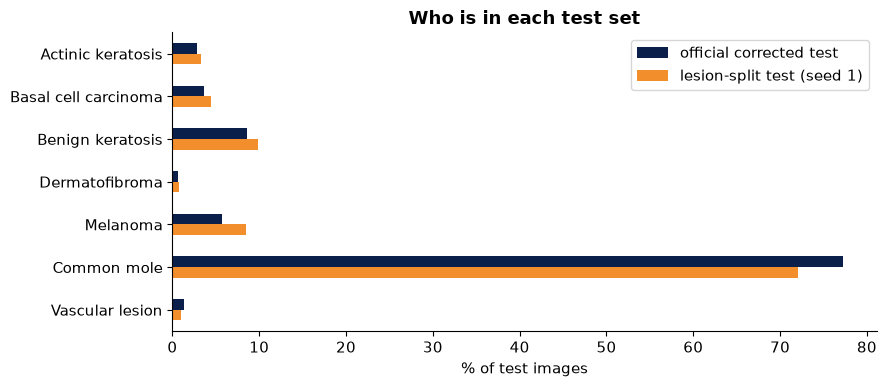

Possibly cancerous: official test 12.1% | lesion-split test 16.3%


In [30]:
lesion_test_cls = np.concatenate([data[s]["cls"] for s in data])[les_te]   # seed 1 test images from section 4.1
comp = pd.DataFrame({"official corrected test": pd.Series(data["test"]["cls"]).value_counts(normalize=True),
                     "lesion-split test (seed 1)": pd.Series(lesion_test_cls).value_counts(normalize=True)}).sort_index()
comp.index = [CLASSES[k].split(" (")[0] for k in comp.index]
ax = (100 * comp).plot.barh(figsize=(9, 4), color=[NAVY, ORANGE]); ax.invert_yaxis()
ax.set_xlabel("% of test images"); ax.set_title("Who is in each test set"); plt.tight_layout(); plt.show()
print(f"Possibly cancerous: official test {100*data['test']['y'].mean():.1f}% | lesion-split test {100*yall[les_te].mean():.1f}%")

**What this shows** (output above)

- Positive images make up 12.1% of the official test set and 16.3% of ours, and the mix of diagnoses differs too
- More positives, or more hard-to-tell diagnoses, change the scores even for an identical model. AUPRC is especially sensitive to the share of positives
- **So what?** A score describes a model *on a particular set of cases*. Scores from two papers with different test sets cannot be compared as if they came from one experiment. The score that matters is the one measured on patients from the clinic that will use the model

## 5. Check changes to training images

**Data augmentation** means training on modified copies of the images, for example rotated or mirrored. The idea: a mole rotated 90 degrees is still the same mole, so the network should learn to ignore orientation. It is a cheap way to get "more" training data

The rule: Choose image changes that preserve task-relevant information, then test whether they improve validation performance

| Change | Same diagnosis afterwards? | Choice for this exercise |
|---|---|---|
| Mirror or rotate by 90 degrees | Yes: a lesion under a dermatoscope has no "up" | Use |
| Small brightness change | Usually, if the detail stays visible | Use with care |
| Strong colour shift | No: colour is a key clue for melanoma | Avoid |
| Grey scale | No: removes colour entirely | Avoid |
| Heavy crop | No: can cut off the border, another key clue | Avoid |

### Test whether image variations help training

First we show what each change does to one lesion. Then we retrain the network *without* mirroring and rotation (the model above used them) and compare. Before running: will augmentation help?

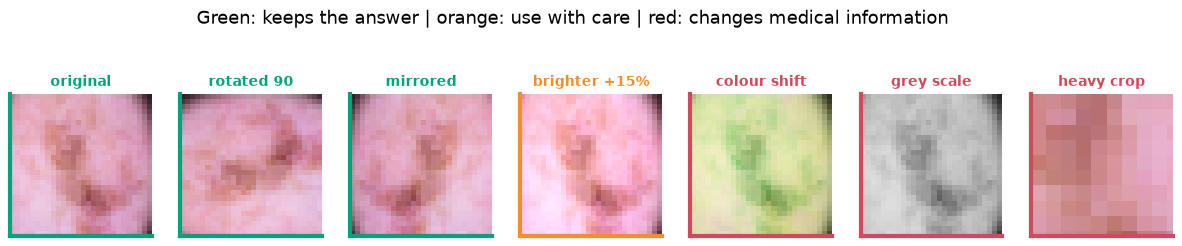

trained 15 epochs in 21 s, selected validation AUROC 0.962, AUPRC 0.744
Test AUROC with mirror/rotate augmentation 0.944 | without 0.952
Test AUPRC with mirror/rotate augmentation 0.665 | without 0.697


In [31]:
import colorsys
im = data["train"]["X"][np.where(data["train"]["cls"] == 4)[0][7]] / 255.0
def hue_shift(a, d): h = np.vectorize(colorsys.rgb_to_hsv)(a[..., 0], a[..., 1], a[..., 2]); return np.stack(np.vectorize(colorsys.hsv_to_rgb)((h[0] + d) % 1, h[1], h[2]), -1)
views = {"original": im, "rotated 90": np.rot90(im), "mirrored": im[:, ::-1], "brighter +15%": np.clip(im * 1.15, 0, 1),
         "colour shift": hue_shift(im, 0.25), "grey scale": np.repeat(im.mean(2, keepdims=True), 3, 2), "heavy crop": np.kron(im[9:19, 9:19], np.ones((3, 3, 1)))[:28, :28]}
ok = {"original": GREEN, "rotated 90": GREEN, "mirrored": GREEN, "brighter +15%": ORANGE, "colour shift": RED, "grey scale": RED, "heavy crop": RED}
fig, axes = plt.subplots(1, 7, figsize=(15, 2.8))
for ax, (k, v) in zip(axes, views.items()):
    ax.imshow(v); ax.set_title(k, color=ok[k], fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_edgecolor(ok[k]); s.set_linewidth(3)
fig.suptitle("Green: keeps the answer | orange: use with care | red: changes medical information", y=1.05); plt.show()

m_noaug, (mu_n, sd_n), _ = train_cnn(data["train"]["X"], data["train"]["y"], data["val"]["X"], data["val"]["y"], use_augment=False, seed=0)
p_noaug = predict_cnn(m_noaug, to_tensor(data["test"]["X"], mu_n, sd_n))
for metric, score in [("AUROC", roc_auc_score), ("AUPRC", average_precision_score)]:
    print(f"Test {metric} with mirror/rotate augmentation {score(yte, p_cnn):.3f} | without {score(yte, p_noaug):.3f}")

**What this shows** (output above)

- The strip shows the same lesion after each change: green is safe, orange needs care, red removes clinical information
- In this run, the network trained **without** augmentation scores slightly higher: AUROC 0.952 versus 0.944, AUPRC 0.697 versus 0.665
- The difference is small and comes from one run of each, so it may be noise
- **So what?** Augmentation is a hypothesis, not a free win. Test it on validation data over several runs, and never choose it by looking at the test set, as we just did for teaching. Whatever you choose, keep the colours and borders doctors rely on

## 6. Takeaways

**Key insights**

- On images, a small CNN clearly beats logistic regression on pixels, because shared filters learn local shapes and borders wherever they appear
- A test is only fair if its cases are truly new to the model: split by lesion, and ideally by patient
- A score belongs to a model *and* a test set. Change the case mix and the score changes, with no change to the model
- Skin tone is not recorded, so performance on darker skin is unknown, and must be reported as unknown

**Common pitfalls**

- Splitting images without keeping photos of the same lesion together
- Comparing scores from different test sets as if they came from the same experiment
- Changing training images in ways that remove useful medical information

**What this means for healthcare decision makers**

- Ask how the data were split, which diagnoses they include and which groups cannot be assessed
- Request testing on data from the intended care setting

**Next session:** we open the network up with explanation maps, and check whether those maps can be trusted

**Check your understanding**

1. Why can the same filter respond to a border in different parts of an image?
2. Why might an image change be acceptable for one medical task but unsuitable for another? Give an example
3. Two papers report different AUROC and AUPRC scores for similar models. What would you check before calling one better?